### Primordial-to-late-time numerical map

In [14]:
import sys
sys.path.append('../scripts')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import camb, classy
from exercise_5 import *

pd.set_option('display.float_format', '{:.6g}'.format)
pd.set_option('display.max_colwidth', 100)
print('CLASS', classy.__version__, '| CAMB', camb.__version__)

CLASS v3.4.1 | CAMB 1.6.5


#### Reconstruction of the matter spectrum

Output tables are written to `ex5_class/output/`

In [3]:
params = read_ini() # physical parameters of fiducial model
fid = run_class(params)   
h = float(params['h'])
pd.Series(record(fid, params)).to_frame('fiducial run')

,fiducial run
code,CLASS v3.4.1 (classy)
output,"tCl,pCl,lCl,mPk,dTk"
lensing,yes
h,0.674
omega_b,0.0224
omega_cdm,0.120
Omega_k,0
N_ur,2.0308
N_ncdm,1
m_ncdm,0.06


$$P_m^{\rm rec}(k,z)=\frac{2\pi^2}{k^3}A_s\left(\frac{k}{k_*}\right)^{n_s-1}T_m^2(k,z) ,\ \ \ \ T_m=\delta_m/\mathcal R$$

610 k values, k_h = 1.05e-05 - 6.69 h/Mpc;  sign of T_m: [-1.]
max |P_rec/P_CLASS - 1| = 6.99e-15


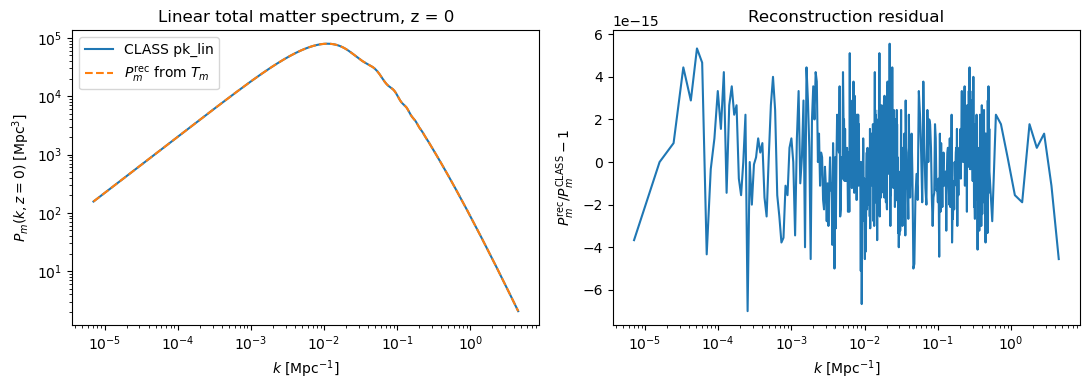

In [5]:
# CLASS d_m is the total-matter density for unit primordial curvature = T_m
# Units: the transfer table is in k_h [hMpc^-1], k=hk_h
# pk_lin(k) takes k in Mpc^-1 and returns P in Mpc^3 
k, T_m, P_rec, P_class = reconstruct(fid, params)   # same k grid (CLASS transfer table)
res = P_rec/P_class - 1
print(f'{k.size} k values, k_h = {k[0]/h:.2e} - {k[-1]/h:.2f} h/Mpc;  sign of T_m: {np.unique(np.sign(T_m))}')
print(f'max |P_rec/P_CLASS - 1| = {np.abs(res).max():.2e}')
np.savetxt(OUTPUT / 'reconstruction.dat', np.column_stack([k, T_m, P_class, P_rec, res]), fmt='%.10e',
           header=f'CLASS {classy.__version__}, z = 0, synchronous gauge, total matter\n'
                  'k[1/Mpc] T_m=d_m P_CLASS[Mpc^3] P_rec[Mpc^3] P_rec/P_CLASS-1')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(k, P_class, label='CLASS pk_lin')
ax[0].loglog(k, P_rec, '--', label=r'$P_m^{\rm rec}$ from $T_m$')
ax[0].set(xlabel=r'$k$ [Mpc$^{-1}$]', ylabel=r'$P_m(k,z=0)$ [Mpc$^3$]', title='Linear total matter spectrum, z = 0')
ax[0].legend()
ax[1].semilogx(k, res)
ax[1].set(xlabel=r'$k$ [Mpc$^{-1}$]', ylabel=r'$P_m^{\rm rec}/P_m^{\rm CLASS}-1$', title='Reconstruction residual')
plt.tight_layout(); plt.show()

#### Identity checks and convergence
CLASS builds pk_lin from the same $T_m$ and $(A_s,n_s,k_*)$ as the reconstruction, so numerical errors in $T_m$ appear on both P_m(k) and get canceled. The residual, then, only tests the normalization ($\mathcal R=1$, $2\pi^2/k^3$) and units ($k=hk_h$, $Mpc^3$).

In [ ]:
# numerical setting in CLASS v3.4.1 that will be varied. 
# reference are the values for tighter settings
# k sampling corresponds to wave-number
pd.DataFrame([(group, name, default, ref) for group, controls in CONTROLS.items()
              for name, (default, ref) in controls.items()],
             columns=['category', 'CLASS parameter', 'default', 'reference'])

,category,CLASS parameter,default,reference
0,ODE tolerance,tol_perturbations_integration,1e-05,1e-07
1,k sampling,k_per_decade_for_pk,10,40
2,k sampling,k_per_decade_for_bao,70,200
3,k sampling,k_step_sub,0.05,0.015
4,time sampling,perturbations_sampling_stepsize,0.1,0.02
5,hierarchy depth,l_max_g,12,40
6,hierarchy depth,l_max_pol_g,10,30
7,hierarchy depth,l_max_ur,17,50
8,hierarchy depth,l_max_ncdm,17,50
9,approximation switches,tight_coupling_trigger_tau_c_over_tau_h,0.015,0.005


In [16]:
kh = np.logspace(-4, np.log10(5), 400) 
kc = h*kh                             
cache = OUTPUT / 'precision_ratios.npz' # saved runs 
if cache.exists():
    ratios = dict(np.load(cache))
else:
    ratios = precision_ratios(params, kc)
    np.savez(cache, **ratios)

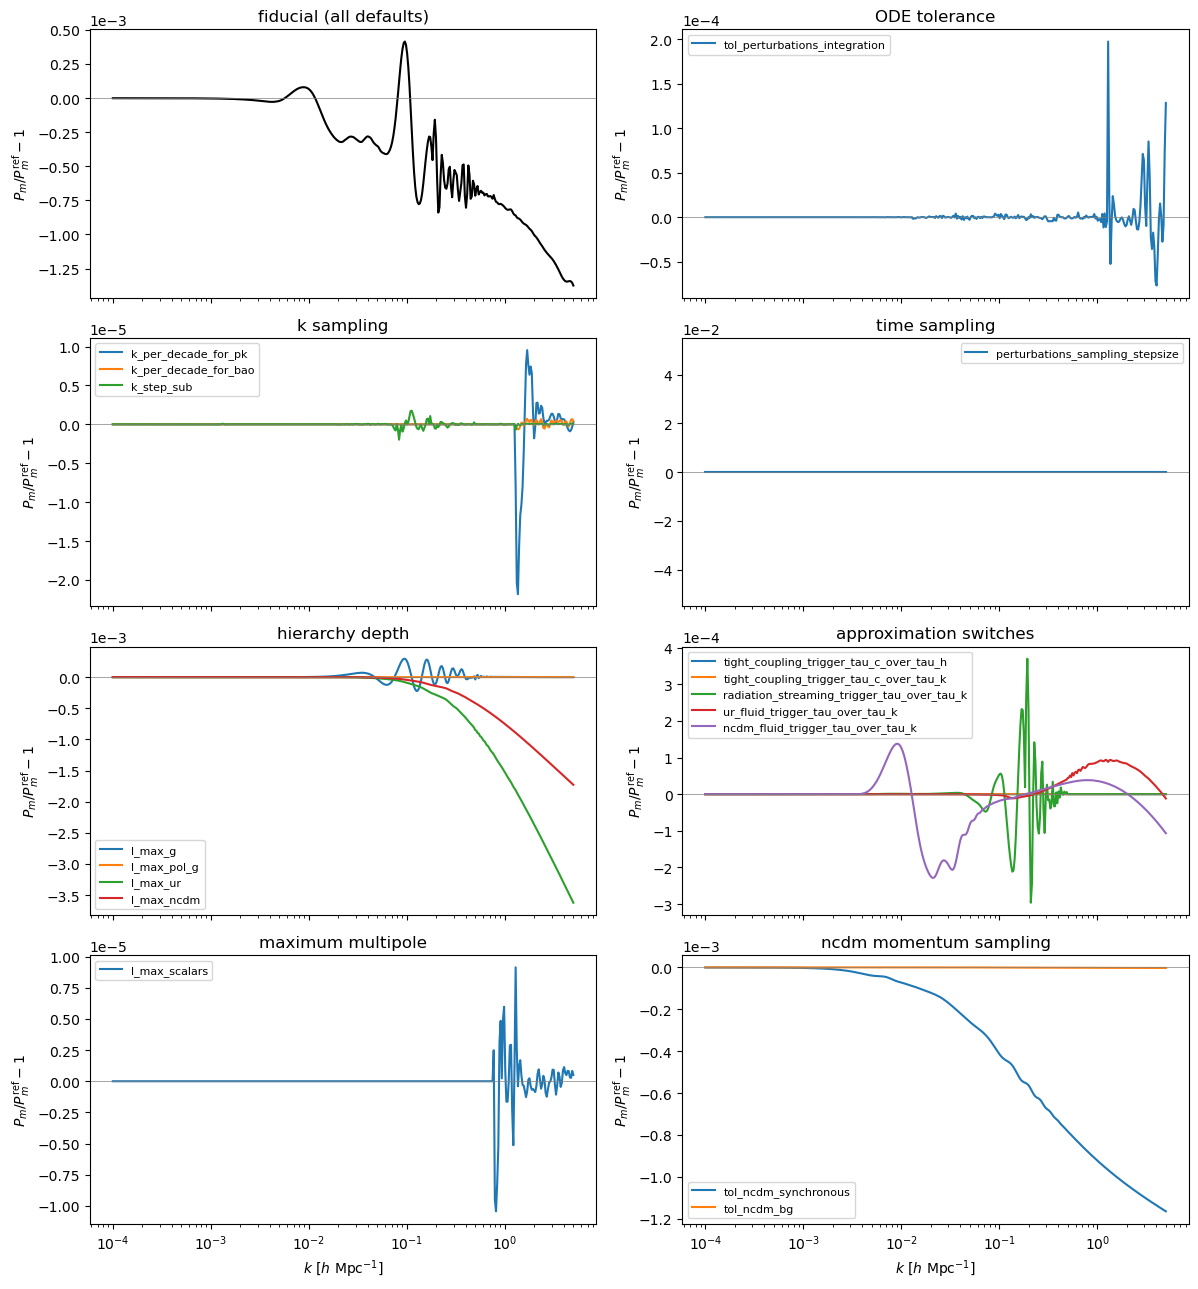

In [17]:
fig, ax = plt.subplots(4, 2, figsize=(12, 13), sharex=True)
ax = ax.ravel()
ax[0].semilogx(kh, ratios['fiducial'] - 1, 'k')
ax[0].set_title('fiducial (all defaults)')
for axis, (group, controls) in zip(ax[1:], CONTROLS.items()):
    for name in controls:
        axis.semilogx(kh, ratios[name] - 1, label=name)
    axis.set_title(group)
    axis.legend(fontsize=8)
for axis in ax:
    axis.axhline(0, color='gray', lw=0.5)
    axis.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    axis.set_ylabel(r'$P_m/P_m^{\rm ref}-1$')
for axis in ax[-2:]:
    axis.set_xlabel(r'$k$ [$h$ Mpc$^{-1}$]')
plt.tight_layout(); plt.show()

In [13]:
# max |P/P_ref - 1| over k ranges
ranges = {'k_h <= 0.1': kh <= 0.1, 'k_h <= 1': kh <= 1, 'k_h <= 5': kh <= 5}
table = pd.DataFrame({name: {r: np.abs(ratios[name][m] - 1).max() for r, m in ranges.items()}
                      for name in ratios if name != 'reference'}).T
table.style.format('{:.1e}')

,k_h <= 0.1,k_h <= 1,k_h <= 5
fiducial,4.1e-04,8.4e-04,1.4e-03
tol_perturbations_integration,4.0e-06,5.3e-06,2.0e-04
k_per_decade_for_pk,0.0e+00,0.0e+00,2.2e-05
k_per_decade_for_bao,0.0e+00,0.0e+00,7.2e-07
k_step_sub,2.0e-06,2.0e-06,2.0e-06
perturbations_sampling_stepsize,0.0e+00,0.0e+00,0.0e+00
l_max_g,3.0e-04,3.0e-04,3.0e-04
l_max_pol_g,1.2e-07,1.2e-07,7.3e-07
l_max_ur,8.6e-05,1.5e-03,3.6e-03
l_max_ncdm,4.2e-05,7.4e-04,1.7e-03


#### Independent implementations

Linear matter spectrum is generated trough CLASS and CAMB with the following physical parameters matched: $h,\omega_b,\omega_c,\Omega_k,A_s,n_s,k_*,\tau_{\rm reio}$, $T_{\rm cmb}$, $Y_{\rm He}$ (CLASS BBN value given to CAMB); neutrinos as $N_{\rm ur}=2.0308$ massless + one massive species with degeneracy $(T_{\rm ncdm}/T_\nu)^4$ and the same $\Omega_{\rm ncdm}h^2$; tanh reionization with the same widths; synchronous gauge, transfers normalized to $\mathcal R=1$; total matter (`d_m` / `delta_tot`); linear; $k$ in $Mpc^{-1}$, $P$ in $Mpc^3$.

In [18]:
fid_rf = run_class(params, {'recombination': 'RECFAST'})                  # CLASS, RECFAST, defaults
ref_rf = run_class(params, {**REFERENCE, 'recombination': 'RECFAST'})     # CLASS, RECFAST, reference
camb_def, camb_high = run_camb(fid_rf, params), run_camb(fid_rf, params, high=True)

P = camb_def.Params   # matched parameter record
d = fid_rf.get_current_derived_parameters(['Neff', 'YHe', 'Omega_Lambda'])
pd.DataFrame({'CLASS': [classy.__version__, h, fid_rf.omega_b(), float(params['omega_cdm']), float(params['Omega_k']),
                        fid_rf.Omega_nu*h**2, d['Neff'], d['YHe'], fid_rf.T_cmb(), float(params['tau_reio']),
                        float(params['A_s']), float(params['n_s']), float(params['k_pivot']), d['Omega_Lambda'],
                        'RECFAST', 'synchronous', 'd_m'],
              'CAMB': [camb.__version__, P.H0/100, P.ombh2, P.omch2, P.omk, P.omnuh2, P.N_eff, P.YHe, P.TCMB,
                       P.Reion.optical_depth, P.InitPower.As, P.InitPower.ns, P.InitPower.pivot_scalar,
                       camb_def.get_Omega('de'), type(P.Recomb).__name__, 'synchronous', 'delta_tot']},
             index=['version', 'h', 'omega_b', 'omega_cdm', 'Omega_k', 'Omega_ncdm h^2', 'N_eff', 'YHe', 'T_cmb [K]',
                    'tau_reio', 'A_s', 'n_s', 'k_pivot [1/Mpc]', 'Omega_Lambda', 'recombination', 'gauge', 'matter'])

,CLASS,CAMB
version,v3.4.1,1.6.5
h,0.674,0.674
omega_b,0.0224,0.0224
omega_cdm,0.12,0.12
Omega_k,0,0
Omega_ncdm h^2,0.000644201,0.000644201
N_eff,3.044,3.044
YHe,0.245288,0.245288
T_cmb [K],2.7255,2.7255
tau_reio,0.054,0.054


sign of T_m:  CLASS [-1.]  CAMB [1.]


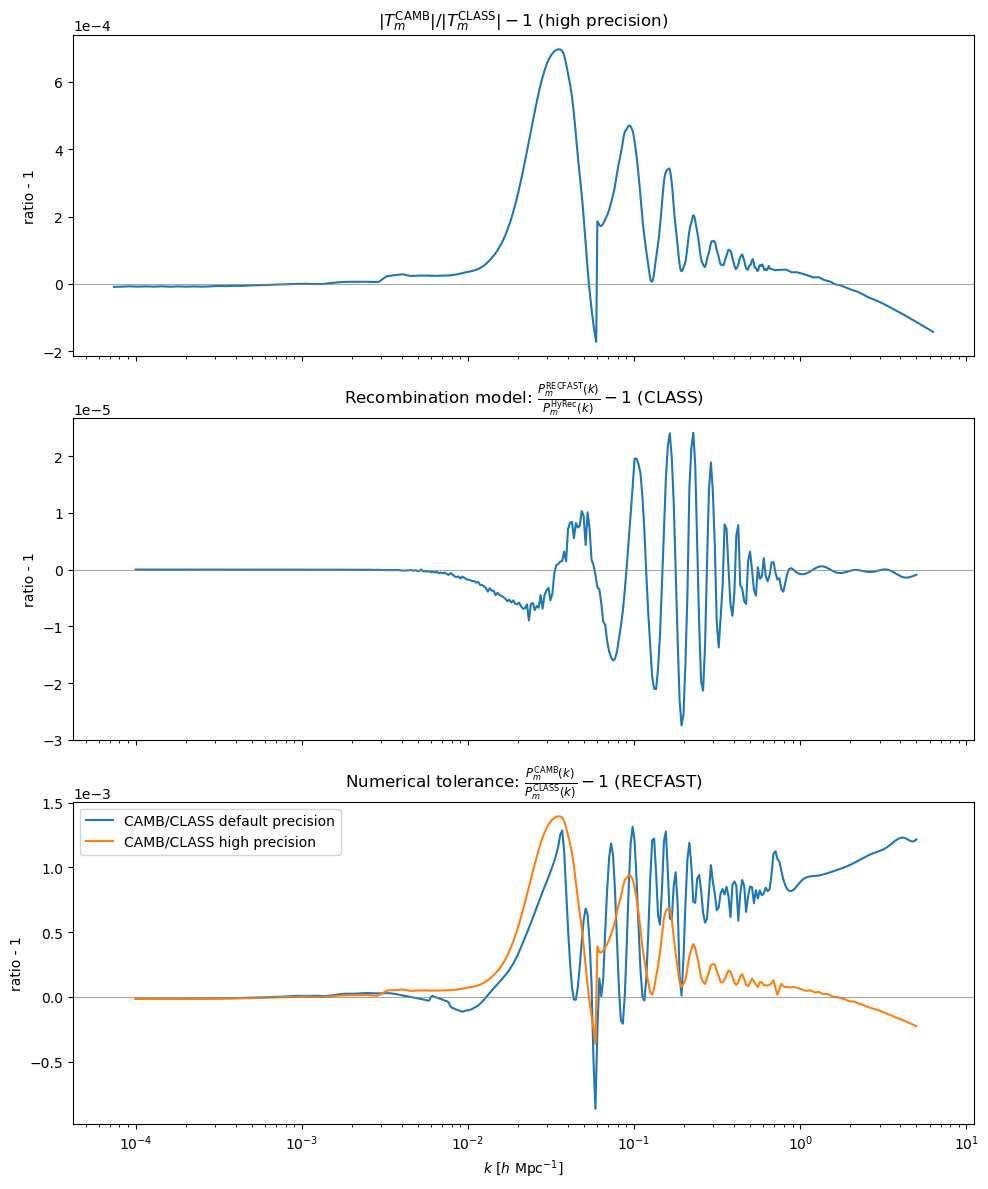

,k_h <= 0.1,k_h <= 1,k_h <= 5
CLASS RECFAST/HyRec (physics),1.6e-05,2.7e-05,2.7e-05
CAMB/CLASS default precision,1.3e-03,1.3e-03,1.3e-03
CAMB/CLASS high precision,1.4e-03,1.4e-03,1.4e-03


In [24]:
# transfer normalization: CAMB T_m vs CLASS d_m at the CAMB k values
k_t, T_camb = camb_transfer(camb_high, h)
T_class = class_transfer_at(ref_rf, h, k_t)
print('sign of T_m:  CLASS', np.unique(np.sign(T_class)), ' CAMB', np.unique(np.sign(T_camb)))

# spectra on the common grid
P_hy = pk_lin(fid, kc)                       # CLASS HyRec, defaults
P_rf, P_rf_ref = pk_lin(fid_rf, kc), pk_lin(ref_rf, kc)
P_cd, P_ch = camb_pk(camb_def, kc), camb_pk(camb_high, kc)
comparison = {'CLASS RECFAST/HyRec (physics)': P_rf/P_hy,
              'CAMB/CLASS default precision': P_cd/P_rf,
              'CAMB/CLASS high precision': P_ch/P_rf_ref}
np.savetxt(OUTPUT / 'class_camb.dat', np.column_stack([kc, *comparison.values()]), fmt='%.10e',
           header='k[1/Mpc] ' + ' | '.join(comparison))

fig, ax = plt.subplots(3, 1, figsize=(10, 12), sharex=True)   # one panel per line
ax[0].semilogx(k_t/h, np.abs(T_camb/T_class) - 1)
ax[0].set(title=r'$|T_m^{\rm CAMB}|/|T_m^{\rm CLASS}|-1$ (high precision)')
ax[1].semilogx(kh, comparison['CLASS RECFAST/HyRec (physics)'] - 1)
ax[1].set(title=r'Recombination model: $\frac{P_m^{\rm RECFAST}(k)}{P_m^{\rm HyRec}(k)} - 1$ (CLASS)')
for label in list(comparison)[1:]:
    ax[2].semilogx(kh, comparison[label] - 1, label=label)
ax[2].set(title=r'Numerical tolerance: $\frac{P_m^{\rm CAMB}(k)}{P_m^{\rm CLASS}(k)} - 1$ (RECFAST)'); ax[2].legend()
for axis in ax:
    axis.axhline(0, color='gray', lw=0.5)
    axis.set_ylabel('ratio - 1')
    axis.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
ax[-1].set_xlabel(r'$k$ [$h$ Mpc$^{-1}$]')   
plt.tight_layout(); plt.show()

pd.DataFrame({label: {r: np.abs(ratio[m] - 1).max() for r, m in ranges.items()}
              for label, ratio in comparison.items()}).T.style.format('{:.1e}')


Top pannel: residual of transfer functions from CAMB and CLASS both computed with tight reference precision settings.

Middle pannel: runs with CLASS with same precision settings and different recombination models (RECFAST and HyRec).

Bottom pannel: residual of matter spectra from CAMB and CLASS computed with same precision settings (one curve for tight reference and one for default) with same recombination model (RECFAST).